# Advanced DSPy & Multi-Question Decision Pipeline with Tev1:4B

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dustinober1/Arg_Me/blob/main/notebooks/05_dspy_tev1_advanced_pipeline.ipynb)

This notebook demonstrates advanced techniques combining **DSPy declarative signatures** with **Together AI's Tev1:4B Decision Model** running via Ollama's `/v1/systemone` endpoint.

### Why Multi-Question Joint Rubrics?
In competitive online debate forums (such as *Debate.org*), errors typically arise from two major sources of discourse complexity:
1. **Procedural Forum Chatter**: Raw scrapes contain non-argumentative text (e.g., *"Resolved: Medicines Should Be Free. I am Con, so Pro should start the argument first..."*, *"Extend..."*, forfeits).
2. **Adversarial Quoting Traps**: Opposing debaters frequently quote and dissect their adversary (e.g., *"Pro claims that X, but this is flawed..."*).

Instead of evaluating stance in isolation, this pipeline asks **three joint questions in a single forward pass**:
- `is_substantive`: Disentangles substantive logical reasoning from procedural negotiations.
- `quotes_opponent`: Detects whether the speaker is attacking an adversary's quotation.
- `stance`: Predicts the author's ultimate argumentative thesis (`PRO` vs `CON`).

In [1]:
# 1. Environment Detection and Dependency Setup
import sys
import os
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')
if IN_COLAB:
    print("Provisioning dependencies inside Google Colab runtime...")
    !pip install -q datasets huggingface_hub pandas pyarrow scikit-learn requests matplotlib seaborn tqdm dspy
    if not os.path.exists('Arg_Me') and not os.path.exists('src'):
        print("Cloning Arg_Me repository into Colab...")
        !git clone https://github.com/dustinober1/Arg_Me.git
        %cd Arg_Me
    elif os.path.exists('Arg_Me') and not os.path.exists('src'):
        %cd Arg_Me
    if '/content/Arg_Me' not in sys.path:
        sys.path.insert(0, '/content/Arg_Me')
    print('Colab environment configured! Current working directory:', os.getcwd())
else:
    print("Running in local environment.")

Running in local environment.


In [2]:
# 2. Imports and Ollama Connectivity Verification
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Ensure project root in sys.path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))

from src.dspy_stance import Tev1MultiQuestionPipeline, ArgumentStanceSignature

# Set Ollama URL (default local instance, or remote tunnel for Colab)
OLLAMA_URL = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434")

try:
    res = requests.get(f"{OLLAMA_URL}/api/tags", timeout=3.0)
    available_models = [m['name'] for m in res.json().get('models', [])]
    print("Connected to Ollama! Available models:", available_models)
    has_tev1 = any('tev1' in m for m in available_models)
    if not has_tev1:
        print("Warning: 'tev1:4b' was not found. Run 'ollama pull tev1:4b' in your terminal.")
except Exception as e:
    print(f"Could not connect to Ollama at {OLLAMA_URL}: {e}")
    print("Make sure Ollama is running ('ollama serve') with 'tev1:4b' pulled.")

Connected to Ollama! Available models: ['tev1:4b', 'gemma4:26b-a4b-it-qat']


In [3]:
# 3. Test Multi-Question Joint Inference on an Edge Case
# We test on a real procedural chatter case that previously fooled baseline models
pipeline = Tev1MultiQuestionPipeline(model_name="tev1:4b", ollama_base_url=OLLAMA_URL)

sample_topic = "Medicines Should Be Made Free"
sample_premise = "Resolved: Medicines Should Be Made Free. I am Con, so Pro should start the argument first."

result = pipeline.forward(sample_topic, sample_premise)

print("=== MULTI-QUESTION JOINT DECISION RESULT ===")
print(f"Predicted Stance:      {result.stance}")
print(f"PRO Probability:       {result.pro_prob:.4f}")
print(f"CON Probability:       {result.con_prob:.4f}")
print(f"Confidence:            {result.confidence:.4f}")
print(f"Content Quality:       {result.is_substantive} (prob = {result.substantive_prob:.4f})")
print(f"Quotes Opponent:       {result.quotes_opponent} (prob = {result.quote_prob:.4f})")
print(f"Inference Latency:     {result.latency_ms:.1f} ms")

2026/10/12 19:58:17 WARNING dspy.primitives.module: Calling module.forward(...) on Tev1MultiQuestionPipeline directly is discouraged. Please use module(...) instead.


=== MULTI-QUESTION JOINT DECISION RESULT ===
Predicted Stance:      CON
PRO Probability:       0.1000
CON Probability:       0.9000
Confidence:            0.2745
Content Quality:       chatter (prob = 0.0180)
Quotes Opponent:       False (prob = 0.1067)
Inference Latency:     309.2 ms


In [4]:
# 4. Load Benchmark Dataset and Configure Evaluation Sample
data_path = Path("../data/args_me_benchmark_5k.parquet")
if not data_path.exists():
    data_path = Path("data/args_me_benchmark_5k.parquet")

df = pd.read_parquet(data_path)
df_clean = df[df["stance"].isin(["PRO", "CON"])].copy().reset_index(drop=True)

# Stratified 20% test split
_, test_df = train_test_split(
    df_clean, test_size=0.20, random_state=42, stratify=df_clean["stance"]
)
print(f"Total held-out test arguments available: {len(test_df)}")

# SET YOUR DESIRED EVALUATION SAMPLE SIZE HERE
# e.g. 50 for a quick 15-second test, or 200 for full statistical evaluation
SAMPLE_SIZE = 50
print(f"Configured evaluation slice: N = {SAMPLE_SIZE}")

Total held-out test arguments available: 1000
Configured evaluation slice: N = 50


In [5]:
# 5. Run the Advanced Pipeline Evaluation
metrics, results_df = pipeline.evaluate_df(test_df, sample_size=SAMPLE_SIZE, random_state=42)

print("\n=== BENCHMARK EVALUATION SUMMARY ===")
print(f"Accuracy:         {metrics.accuracy:.4f} ({metrics.accuracy * 100:.2f}%)")
print(f"Macro F1:         {metrics.macro_f1:.4f}")
print(f"Macro Precision:  {metrics.macro_precision:.4f}")
print(f"Macro Recall:     {metrics.macro_recall:.4f}")
print(f"CON F1:           {metrics.con_f1:.4f} | PRO F1: {metrics.pro_f1:.4f}")
print(f"ROC-AUC:          {metrics.roc_auc:.4f}")
print(f"Average Latency:  {results_df['latency_ms'].mean():.1f} ms per decision")


Evaluating Advanced DSPy/Tev1 Pipeline on 50 arguments...


Advanced Multi-Question Pipeline: 100%|██████████| 50/50 [00:27<00:00,  1.85it/s]


Advanced Pipeline Results:
Accuracy: 0.6600 | Macro F1: 0.6599 | ROC-AUC: 0.7019
Mean Latency: 539.5 ms | Chatter Detected: 30.0% | Opponent Quotes: 40.0%

=== BENCHMARK EVALUATION SUMMARY ===
Accuracy:         0.6600 (66.00%)
Macro F1:         0.6599
Macro Precision:  0.6600
Macro Recall:     0.6603
CON F1:           0.6667 | PRO F1: 0.6531
ROC-AUC:          0.7019
Average Latency:  539.5 ms per decision


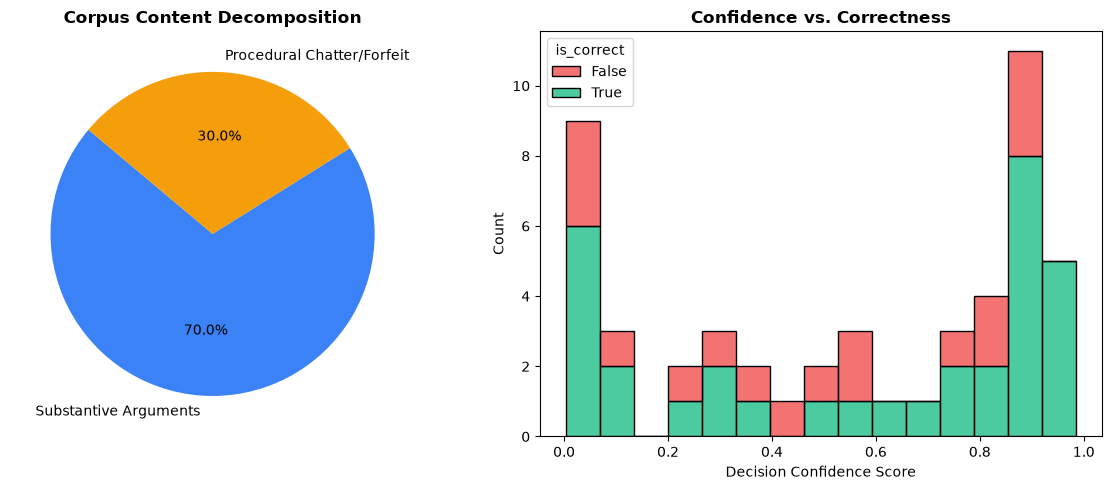

In [6]:
# 6. Dialectic Diagnostic Distribution
chatter_count = (results_df["is_substantive"] == "chatter").sum()
quote_count = results_df["quotes_opponent"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart of substantive vs chatter
ax1.pie(
    [len(results_df) - chatter_count, chatter_count],
    labels=["Substantive Arguments", "Procedural Chatter/Forfeit"],
    autopct="%1.1f%%",
    colors=["#3b82f6", "#f59e0b"],
    startangle=140,
)
ax1.set_title("Corpus Content Decomposition", fontweight="bold")

# Distribution of Tev1 Confidence
sns.histplot(data=results_df, x="confidence", hue="is_correct", bins=15, multiple="stack", palette={True: "#10b981", False: "#ef4444"}, ax=ax2)
ax2.set_title("Confidence vs. Correctness", fontweight="bold")
ax2.set_xlabel("Decision Confidence Score")

plt.tight_layout()
plt.show()

In [7]:
# 7. Qualitative Review: Inspect Predictions and Dialectic Labels
preview_cols = ["conclusion", "premise_text", "stance", "pred_stance", "is_substantive", "quotes_opponent", "confidence", "is_correct"]
results_df[preview_cols].head(8)

,conclusion,premise_text,stance,pred_stance,is_substantive,quotes_opponent,confidence,is_correct
0,The Pharoah's of Ancient Egypt were NOT black,There is an awful amount of misinformation out...,PRO,PRO,substantive,True,0.314645,True
1,Should probable cause be used in U.S. schools ...,BEFORE WE BEGIN PLEASE NOTE THAT THE FIRST ROU...,PRO,PRO,substantive,False,0.893336,True
2,Anybody who used performance enhancing drugs i...,The Hall of Fame is merely glorifying the bigg...,CON,CON,substantive,False,0.011184,True
3,Medicines Should Be Made Free,Resolved: Medicines Should Be Made FreeI am Co...,CON,CON,chatter,False,0.234933,True
4,Prescriptive Grammar does more harm than good,"""I challenge my opponent to come up with a 'sl...",CON,CON,substantive,True,0.125896,True
5,Christianity has had more positive than negati...,The burden of proof is on me. If I can prove t...,PRO,PRO,chatter,False,0.826306,True
6,I can post the stupidest video,Just post a really stupid video and we will le...,PRO,PRO,chatter,False,0.510148,True
7,School uniforms should be banned.,Welcome temmo I heavily apologize im a newcome...,PRO,PRO,substantive,False,0.882207,True
